In [15]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

In [16]:
def standardize_spectrum(X):
    mean = np.nanmean(X, axis=1, keepdims=True)
    std = np.nanstd(X, axis=1, keepdims=True)

    std[std == 0] = 1.0

    X_std = (X - mean) / std
    X_std[~np.isfinite(X_std)] = 0.0

    return X_std.astype(np.float32)

In [17]:
def FNN(input_dim, dropout_rate):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-5)),
        layers.Dropout(dropout_rate),
        layers.Dense(32, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-5)),
        layers.Dropout(dropout_rate),
        layers.Dense(4, activation="softmax")])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
        loss="categorical_crossentropy",
        metrics=[
            tf.keras.metrics.CategoricalAccuracy(),
            tf.keras.metrics.MeanAbsoluteError(name = "mae")])

    return model

In [18]:
def count_dominant_classes(y_split, split_name, class_names):
    dominant_indices = np.argmax(y_split, axis=1)
    counts = pd.Series(dominant_indices).value_counts().sort_index()

    result = pd.DataFrame({
        "class": class_names,
        "count": [counts.get(i, 0) for i in range(len(class_names))]})

    result["percentage"] = 100 * result["count"] / len(y_split)

    print(f"\n{split_name}:")
    print(result.to_string(index=False))

In [19]:
class_names = ["HII", "PN", "SNR", "DIG"]

data_dir = Path("../Mock Spectra")

X = np.load(data_dir / "mock_spectra_combined.npy")
y = np.load(data_dir / "mock_spectra_combined_weights.npy")
metadata = pd.read_csv(data_dir / "mock_spectra_combined_metadata.csv")

X = X.astype(np.float32)
y = y.astype(np.float32)

print("X shape:", X.shape)
print("Y shape:", y.shape)

X shape: (10000, 3841)
Y shape: (10000, 4)


In [20]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [21]:
X = standardize_spectrum(X)

#dominant_class = np.argmax(y, axis=1)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    shuffle=True,
    #stratify=dominant_class
    )

#temp_dominant_class = np.argmax(y_temp, axis=1)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    shuffle=True,
    #stratify=temp_dominant_class
    )

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

count_dominant_classes(y_train, "Training set", class_names)
count_dominant_classes(y_val, "Validation set", class_names)
count_dominant_classes(y_test, "Test set", class_names)

Train: (7000, 3841) (7000, 4)
Val:   (1500, 3841) (1500, 4)
Test:  (1500, 3841) (1500, 4)

Training set:
class  count  percentage
  HII   1732   24.742857
   PN   1750   25.000000
  SNR   1761   25.157143
  DIG   1757   25.100000

Validation set:
class  count  percentage
  HII    371   24.733333
   PN    349   23.266667
  SNR    388   25.866667
  DIG    392   26.133333

Test set:
class  count  percentage
  HII    399   26.600000
   PN    368   24.533333
  SNR    362   24.133333
  DIG    371   24.733333


In [22]:
model = FNN(X.shape[1], dropout_rate=0.3)
model.summary()

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=256,
    callbacks=[early_stop])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │       245,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 248,100 (969.14 KB)

 Trainable params: 248,100 (969.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - categorical_accuracy: 0.2526 - loss: 1.8172 - mae: 0.2001 - val_categorical_accuracy: 0.2680 - val_loss: 1.5709 - val_mae: 0.1664
Epoch 2/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - categorical_accuracy: 0.2511 - loss: 1.7357 - mae: 0.1882 - val_categorical_accuracy: 0.2733 - val_loss: 1.5147 - val_mae: 0.1516
Epoch 3/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - categorical_accuracy: 0.2463 - loss: 1.6684 - mae: 0.1777 - val_categorical_accuracy: 0.2707 - val_loss: 1.4800 - val_mae: 0.1419
Epoch 4/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.2446 - loss: 1.6222 - mae: 0.1689 - val_categorical_accuracy: 0.2693 - val_loss: 1.4567 - val_mae: 0.1351
Epoch 5/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.2451 - loss: 1.5872 - mae: 0.1627 - val_categorical_accuracy: 0.2660 - val_loss: 1.4411 - val_mae: 0.1306
Epoch 6/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - categorical_accuracy: 0.2573 - l

In [23]:
test_results = model.evaluate(X_test, y_test, return_dict=True)
print("Test metrics:")
for name, value in test_results.items():
    print(f"  {name}: {value:.4f}")

y_pred = model.predict(X_test)

y_true_class = np.argmax(y_test, axis=1)
y_pred_class = np.argmax(y_pred, axis=1)

print(classification_report(
    y_true_class,
    y_pred_class,
    target_names=class_names,
    digits=3))

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 439us/step - categorical_accuracy: 0.4007 - loss: 1.3727 - mae: 0.1069
Test metrics:
  categorical_accuracy: 0.4007
  loss: 1.3727
  mae: 0.1069
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 490us/step
              precision    recall  f1-score   support

         HII      0.380     0.175     0.240       399
          PN      0.408     0.690     0.513       368
         SNR      0.368     0.406     0.386       362
         DIG      0.442     0.350     0.391       371

    accuracy                          0.401      1500
   macro avg      0.400     0.406     0.383      1500
weighted avg      0.399     0.401     0.380      1500



In [24]:
absolute_errors = np.abs(y_test - y_pred)
median_absolute_error = np.median(absolute_errors, axis=0)
mean_absolute_error = np.mean(absolute_errors, axis=0)

weight_error_table = pd.DataFrame({
    "class": class_names,
    "median_absolute_error": median_absolute_error,
    "mean_absolute_error": mean_absolute_error,
    "median_error_percent": 100 * median_absolute_error})

print("Overall median absolute error:", np.median(absolute_errors))
weight_error_table

Overall median absolute error: 0.09350569


,class,median_absolute_error,mean_absolute_error,median_error_percent
0,HII,0.099196,0.114142,9.919620
1,PN,0.085655,0.098473,8.565454
2,SNR,0.092887,0.104841,9.288664
3,DIG,0.095719,0.109953,9.571939


In [25]:
prevalent_mask = np.max(y_test, axis=1) > 0.5

print("Spectra with a weight > 0.5:", prevalent_mask.sum())
print(classification_report(
    y_true_class[prevalent_mask],
    y_pred_class[prevalent_mask],
    target_names=class_names,
    digits=3))

Spectra with a weight > 0.5: 257
              precision    recall  f1-score   support

         HII      0.486     0.243     0.324        74
          PN      0.543     0.838     0.659        68
         SNR      0.411     0.548     0.469        42
         DIG      0.593     0.479     0.530        73

    accuracy                          0.518       257
   macro avg      0.508     0.527     0.496       257
weighted avg      0.519     0.518     0.495       257



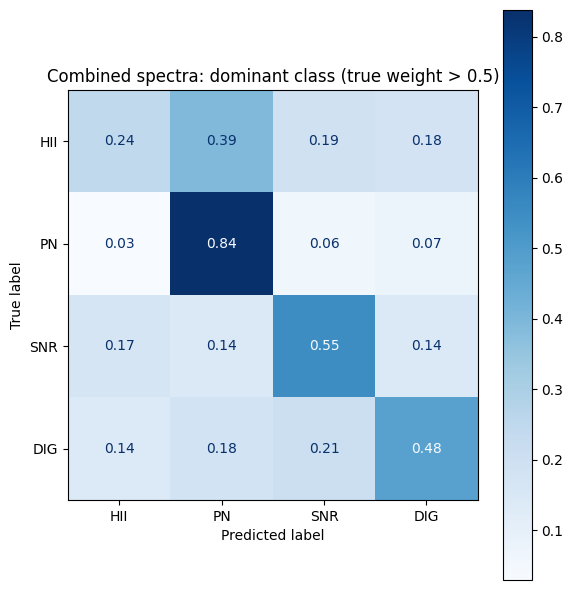

In [26]:
cm = confusion_matrix(
    y_true_class[prevalent_mask],
    y_pred_class[prevalent_mask],
    normalize="true")

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, values_format=".2f", cmap="Blues")
plt.title("Combined spectra: dominant class (true weight > 0.5)")
plt.tight_layout()
plt.show()

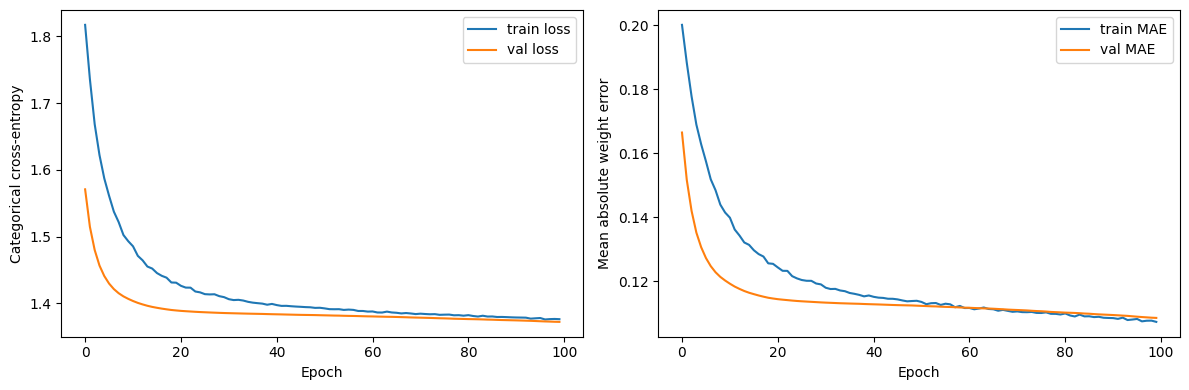

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="train loss")
axes[0].plot(history.history["val_loss"], label="val loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Categorical cross-entropy")
axes[0].legend()

axes[1].plot(history.history["mae"], label="train MAE")
axes[1].plot(history.history["val_mae"], label="val MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean absolute weight error")
axes[1].legend()

plt.tight_layout()
plt.show()

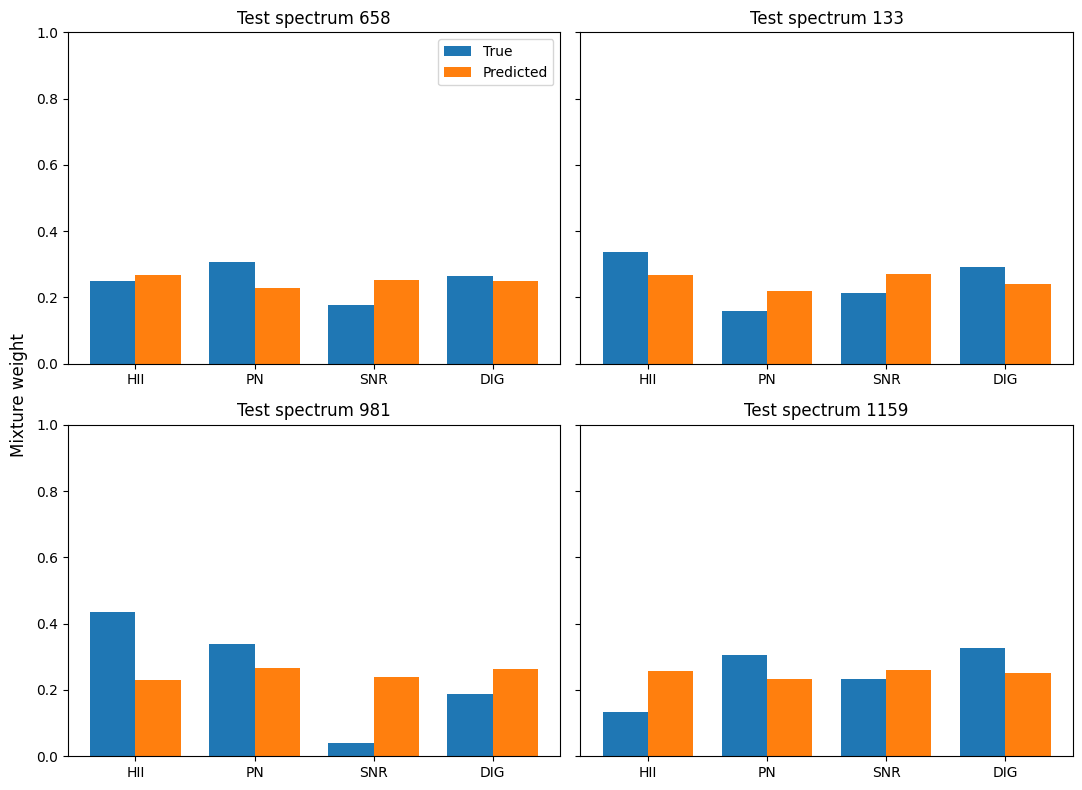

In [28]:
rng = np.random.default_rng(SEED)
example_indices = rng.choice(len(y_test), size=4, replace=False)
x_positions = np.arange(len(class_names))
bar_width = 0.38

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)

for ax, index in zip(axes.flat, example_indices):
    ax.bar(
        x_positions - bar_width / 2,
        y_test[index],
        width=bar_width,
        label="True")
    ax.bar(
        x_positions + bar_width / 2,
        y_pred[index],
        width=bar_width,
        label="Predicted")
    ax.set_xticks(x_positions, class_names)
    ax.set_ylim(0, 1)
    ax.set_title(f"Test spectrum {index}")

axes[0, 0].legend()
fig.supylabel("Mixture weight")
plt.tight_layout()
plt.show()

In [ ]:
model.save("fnn_combined_spectra.keras")